# Conditional HuProSO3 flow: inverse kinematics with an occlusion

How the keypoint conditions work on the normalizing flow of the HuProSO3 paper, before we train our own conditional models (`docs/rsgm_conditioning.md`). The flow is the authors' pretrained model for inverse kinematics with occlusions, `id_0384`: conditioned on the 3D positions of the 22 SMPL joints, trained with random masks of hidden joints (§4.3 of the paper). One model handles any occlusion.

What the notebook does:
1. loads the flow (the checkpoint format of the paper's code) and checks that our `hp.data.conditions.keypoints` gives the same condition the flow was trained with;
2. takes one test pose, hides a group of joints (`OCCLUSION`), and draws `N_SAMPLES` poses from p(pose | visible keypoints);
3. shows them: the skeletons on top of each other, the meshes, and the spread per joint;
4. evaluates the occlusions of the paper on `N_EVAL` test poses: MPJPE and MGEO of one sample, of the mean of 10 samples and of the best of 10, next to Tab. 3 of the paper.

**Conventions of the paper's code, kept here:**
- the condition is the 66 numbers of `perform_forward_kinematics` (22 joints × 3, meters, root at the origin);
- a hidden joint is a keypoint set to 0 (this model has no mask input and no −1e5 offset);
- MPJPE is the mean over the 22 keypoints (the root included), MGEO the mean geodesic angle over the 19 joints;
- "mean of 10" is one pose: the mean rotation of every joint over the 10 samples (`scipy Rotation.mean`, the chordal mean).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import roma
import torch
from omegaconf import OmegaConf

import hp.estimators.rotnorm.utils.sd as sd
from hp.data.amass_cfg import AmassJoints, AmassJoints4Learning
from hp.data.conditions import keypoints
from hp.estimators.rotnorm.flow.flow_nd import get_nd_flow
from hp.estimators.simple_mlp import MLPTransform
from hp.evaluation.data import load_reference
from hp.utils.paths import REPO_ROOT, get_path
from hp.utils.skeleton_forward_kinematics import SkelForwardKinematics, perform_forward_kinematics

# ---- parameters ----------------------------------------------------------------------
MODEL = REPO_ROOT / "experiments" / "pretrained_models" / "id_0384"  # the authors' flow: 3D keypoints, random masks
TEST_ROTATIONS = "~/data/AMASS_rotations"   # the official test split (Transitions + SSM), all frames
# The occlusions of the paper (Tab. 3; the joint names of the paper's code, explore/evaluate.ipynb), by the keypoints
# they hide. Add your own: any names of AmassJoints.
OCCLUSIONS = {
    "none": [],
    "L (left leg)": ["LeftUpLeg", "LeftLeg", "LeftFoot"],
    "A+H (left arm and hand)": ["LeftArm", "LeftElbow", "LeftHand"],
    "S+UA (right shoulder, upper arm)": ["RightShoulder", "RightArm"],
}
OCCLUSION = "A+H (left arm and hand)"       # the one of sections 2-3
POSE_SEED = 3                               # which test pose (a random one, from this seed)
N_SAMPLES = 10                              # samples of that pose
N_EVAL = 1000                               # test poses of section 4
K = 10                                      # samples per pose in section 4 ("mean of 10", "best of 10")
SEED = 0
DEVICE = "cpu"
VIEWS = (0, 90)                             # azimuths of the mesh renders (degrees)
# ----------------------------------------------------------------------------------------

torch.manual_seed(SEED)
J = len(AmassJoints4Learning)
PARENTS = SkelForwardKinematics().parents[:22]
NAMES22 = [AmassJoints(i).name for i in range(22)]

## 1. The model

The flow and its condition MLP are built from the config of the run and loaded from its two checkpoints, as `CondSO3PriorTrainer.load_model` does (without the trainer, which would load the datasets). `sample` pushes uniform rotations through the inverse flow; `log_prob` is the exact log-likelihood log p(pose | c), relative to the uniform distribution on SO(3)^19.

In [2]:
def load_conditional_flow(folder, device="cpu"):
    folder = Path(folder)
    config = OmegaConf.load(folder / "config.yaml")
    so3 = config.so3
    so3.n_dim, so3.save_path_dir = J, str(folder)
    flow = get_nd_flow(so3).to(device)
    flow.load_state_dict(torch.load(folder / "model_ckpt_pdf_estimator.pt", map_location=device))
    flow.permute_dims = np.loadtxt(folder / "permute_dims.pt")
    mlp = MLPTransform(so3.dim_cond_feature, so3.feature_channels, Nh=config.conditioning.hidden_mlp_dims,
                       num_hid_layers=config.conditioning.num_hid_layers).to(device)
    mlp.load_state_dict(torch.load(folder / "model_ckpt_feature_extractor.pt", map_location=device))
    return flow.eval(), mlp.eval(), config


flow, cond_mlp, config = load_conditional_flow(MODEL, DEVICE)
assert config.conditioning.conditioning_modality == "3D" and not config.conditioning.get("mask_neg_offset", False)
print(f"{MODEL.name}: {sum(p.numel() for p in flow.parameters()) + sum(p.numel() for p in cond_mlp.parameters()):,} parameters, "
      f"trained with masks: {config.conditioning.mask} ({config.conditioning.mask_type}, vary_mask_prob {config.conditioning.vary_mask_prob})")


def features(kp, hidden=()):
    # condition features [B, 64] of keypoints [B, 22, 3] with the joints `hidden` (indices 0-21) set to 0
    kp = kp.clone()
    kp[:, list(hidden)] = 0
    return cond_mlp(kp.reshape(len(kp), -1).to(DEVICE))


@torch.no_grad()
def sample(kp, hidden=(), k=1):
    # k poses [B, k, 19, 3, 3] for each condition of kp [B, 22, 3], and their log-likelihoods [B, k]
    f = features(kp, hidden).repeat_interleave(k, 0)
    base = torch.stack([sd.generate_queries(len(f), mode="random") for _ in range(J)]).permute(1, 0, 2, 3).to(DEVICE)
    poses, neg_log_p = flow.inverse(base, f)  # the inverse pass returns -log p (checked against log_prob of the samples)
    return poses.reshape(len(kp), k, J, 3, 3).cpu(), -neg_log_p.reshape(len(kp), k).cpu()


@torch.no_grad()
def log_prob(poses, kp, hidden=()):
    return flow(poses.to(DEVICE), feature=features(kp, hidden))[1].cpu()


def hidden_indices(occlusion):
    return [AmassJoints[name].value for name in OCCLUSIONS[occlusion]]


test = load_reference("test", TEST_ROTATIONS, "original")
check = test[:500]
difference = (keypoints(check) - perform_forward_kinematics(check, selected_joints=AmassJoints4Learning)).abs().max()
print(f"test: {len(test):,} poses; our keypoints vs the paper's FK on 500 poses: max difference {difference * 1000:.4f} mm")

id_0384: 1,517,104 parameters, trained with masks: True (random, vary_mask_prob True)
test: 117,679 poses; our keypoints vs the paper's FK on 500 poses: max difference 0.0002 mm


## 2. One pose, one occlusion

The ground truth, its keypoints with the hidden ones removed, and `N_SAMPLES` poses from p(pose | visible keypoints). For every sample: the MPJPE of the visible and of the hidden keypoints, the MGEO, and the log-likelihood. The visible part should be reproduced closely, the hidden part should vary.

In [3]:
def geodesic(a, b):
    # angle [...] between rotations a, b [..., 3, 3]
    return roma.rotmat_geodesic_distance(a, b)


def mean_rotation(poses):
    # the chordal mean (as scipy Rotation.mean) over dim 1 of poses [B, k, J, 3, 3] -> [B, J, 3, 3]
    q = roma.rotmat_to_unitquat(poses.double())                              # [B, k, J, 4]
    m = torch.einsum("bkji,bkjl->bjil", q, q)                                 # sum of q q^T
    top = torch.linalg.eigh(m).eigenvectors[..., -1]                         # eigenvector of the largest eigenvalue
    return roma.unitquat_to_rotmat(top).float()


hidden = hidden_indices(OCCLUSION)
visible = [j for j in range(22) if j not in hidden]
index = torch.randint(len(test), (1,), generator=torch.Generator().manual_seed(POSE_SEED)).item()
gt = test[index : index + 1]
kp = keypoints(gt)
torch.manual_seed(SEED)
samples, sample_ll = sample(kp, hidden, N_SAMPLES)
samples, sample_ll = samples[0], sample_ll[0]                                # [N, 19, 3, 3], [N]
kp_samples = keypoints(samples)                                              # [N, 22, 3]
err = (kp_samples - kp).norm(dim=-1) * 1000                                  # mm [N, 22]
mgeo = geodesic(samples, gt).mean(-1)                                        # rad [N]
gt_ll = log_prob(gt, kp, hidden)[0]
mean_pose = mean_rotation(samples[None])
mean_err = (keypoints(mean_pose) - kp).norm(dim=-1)[0] * 1000

print(f"test pose #{index}, occlusion {OCCLUSION}: hidden keypoints {[NAMES22[j] for j in hidden]}")
print(f"log p(ground truth | visible keypoints) = {gt_ll:.1f}\n")
print(f"{'sample':>8s} {'MPJPE visible':>14s} {'MPJPE hidden':>13s} {'MPJPE all':>10s} {'MGEO':>7s} {'log p':>8s}")
for i in range(N_SAMPLES):
    print(f"{i:8d} {err[i, visible].mean():11.1f} mm {err[i, hidden].mean() if hidden else 0:10.1f} mm "
          f"{err[i].mean():7.1f} mm {mgeo[i]:7.3f} {sample_ll[i]:8.1f}")
print(f"{'mean':>8s} {mean_err[visible].mean():11.1f} mm {mean_err[hidden].mean() if hidden else 0:10.1f} mm "
      f"{mean_err.mean():7.1f} mm {geodesic(mean_pose, gt).mean():7.3f}   (the mean pose of the {N_SAMPLES} samples)")

test pose #75728, occlusion A+H (left arm and hand): hidden keypoints ['LeftArm', 'LeftElbow', 'LeftHand']
log p(ground truth | visible keypoints) = 135.9

  sample  MPJPE visible  MPJPE hidden  MPJPE all    MGEO    log p
       0        50.1 mm      347.7 mm    90.7 mm   0.297    153.6
       1        34.7 mm      465.6 mm    93.5 mm   0.365    160.5
       2        35.3 mm      243.4 mm    63.7 mm   0.407    161.0
       3        26.2 mm      380.7 mm    74.5 mm   0.451    151.1
       4        29.6 mm      267.9 mm    62.1 mm   0.433    151.5
       5        41.0 mm      479.5 mm   100.8 mm   0.472    161.6
       6        40.5 mm      432.5 mm    94.0 mm   0.427    145.5
       7        38.6 mm      308.2 mm    75.3 mm   0.403    159.7
       8        34.4 mm      372.8 mm    80.5 mm   0.452    143.6
       9        32.1 mm      447.2 mm    88.7 mm   0.404    152.0
    mean        29.6 mm      369.1 mm    75.9 mm   0.327   (the mean pose of the 10 samples)


## 3. Pictures

**Skeletons on top of each other** (front and side): the ground truth in black, the samples in color, the hidden keypoints of the ground truth as red rings. The visible part of the samples should lie on the ground truth, the hidden part should fan out.

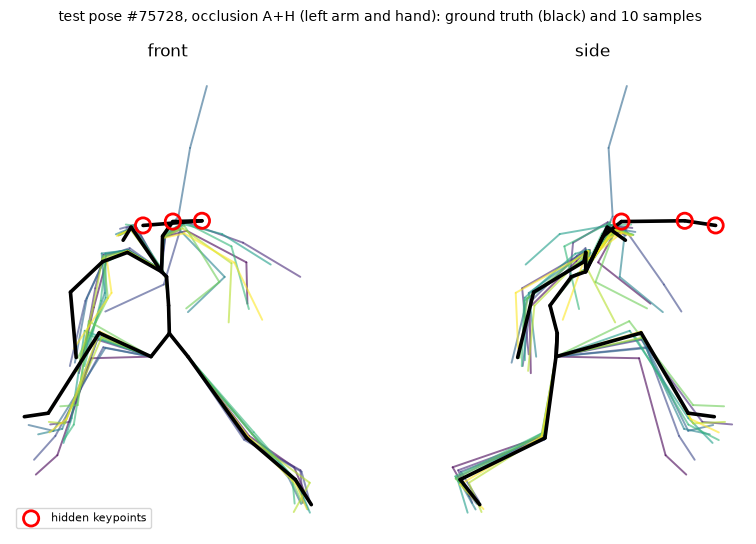

In [4]:
def draw(ax, joints, view, **style):
    a, b = (0, 1) if view == "front" else (2, 1)
    for j in range(1, 22):
        p = PARENTS[j]
        ax.plot([joints[j, a], joints[p, a]], [joints[j, b], joints[p, b]], solid_capstyle="round", **style)


fig, axes = plt.subplots(1, 2, figsize=(9, 5.5))
for ax, view in zip(axes, ("front", "side")):
    for i in range(N_SAMPLES):
        draw(ax, kp_samples[i].numpy(), view, color=plt.cm.viridis(i / max(N_SAMPLES - 1, 1)), lw=1.4, alpha=0.6)
    draw(ax, kp[0].numpy(), view, color="k", lw=2.6)
    a, b = (0, 1) if view == "front" else (2, 1)
    if hidden:
        ax.scatter(kp[0, hidden, a], kp[0, hidden, b], s=120, facecolors="none", edgecolors="red", linewidths=2, zorder=5,
                   label="hidden keypoints")
    ax.set_aspect("equal")
    ax.set_title(view)
    ax.axis("off")
axes[0].legend(loc="lower left", fontsize=8)
fig.suptitle(f"test pose #{index}, occlusion {OCCLUSION}: ground truth (black) and {N_SAMPLES} samples", fontsize=10)
fig.tight_layout()
plt.show()

**Meshes** (if the SMPL-X body model is in `body_models`; else this cell says so): the ground truth, then the samples with their log-likelihood.

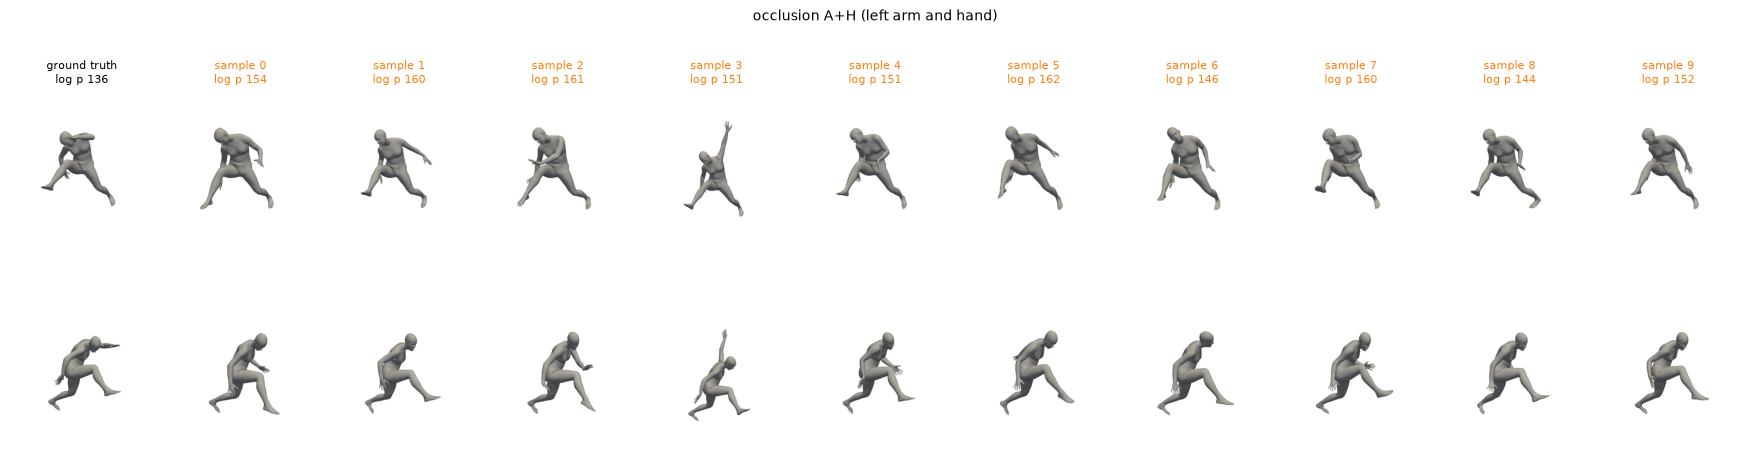

In [5]:
BODY_MODEL = Path(get_path("body_models")) / "smplx" / "SMPLX_NEUTRAL.npz"


def to_pose_body(poses):
    # [N, 19, 3, 3] -> [N, 63]: axis-angle of the 21 body joints of SMPL-X, the toes (10, 11) at rest
    pose_body = torch.zeros(len(poses), 21, 3)
    pose_body[:, [j.value - 1 for j in AmassJoints4Learning]] = roma.rotmat_to_rotvec(poses.float().cpu())
    return pose_body.reshape(len(poses), 63)


if BODY_MODEL.is_file():
    from hp.visualization.render_tools import HumanRender
    renderer = HumanRender()
    shown = torch.cat([gt, samples])
    images = renderer.render_images(to_pose_body(shown), azimuths_deg=list(VIEWS))      # [N + 1, views, h, w, 3]
    titles = [f"ground truth\nlog p {gt_ll:.0f}"] + [f"sample {i}\nlog p {sample_ll[i]:.0f}" for i in range(N_SAMPLES)]
    fig, axes = plt.subplots(len(VIEWS), len(shown), figsize=(1.6 * len(shown), 2.6 * len(VIEWS)), squeeze=False)
    for i in range(len(shown)):
        for r in range(len(VIEWS)):
            axes[r, i].imshow(images[i, r])
            axes[r, i].axis("off")
        axes[0, i].set_title(titles[i], fontsize=8, color="k" if i == 0 else "C1")
    fig.suptitle(f"occlusion {OCCLUSION}", fontsize=10)
    fig.tight_layout()
    plt.show()
else:
    print(f"no body model at {BODY_MODEL}: no meshes (the skeletons above show the same)")

**Spread per joint**: how far the samples are from the ground truth, per keypoint (MPJPE, mm) and per joint rotation (geodesic angle, degrees). Hidden keypoints in red. Note the joints that the keypoints cannot see even without an occlusion: the wrists (LeftHand, RightHand) and the head have no child keypoint, so their rotations are free.

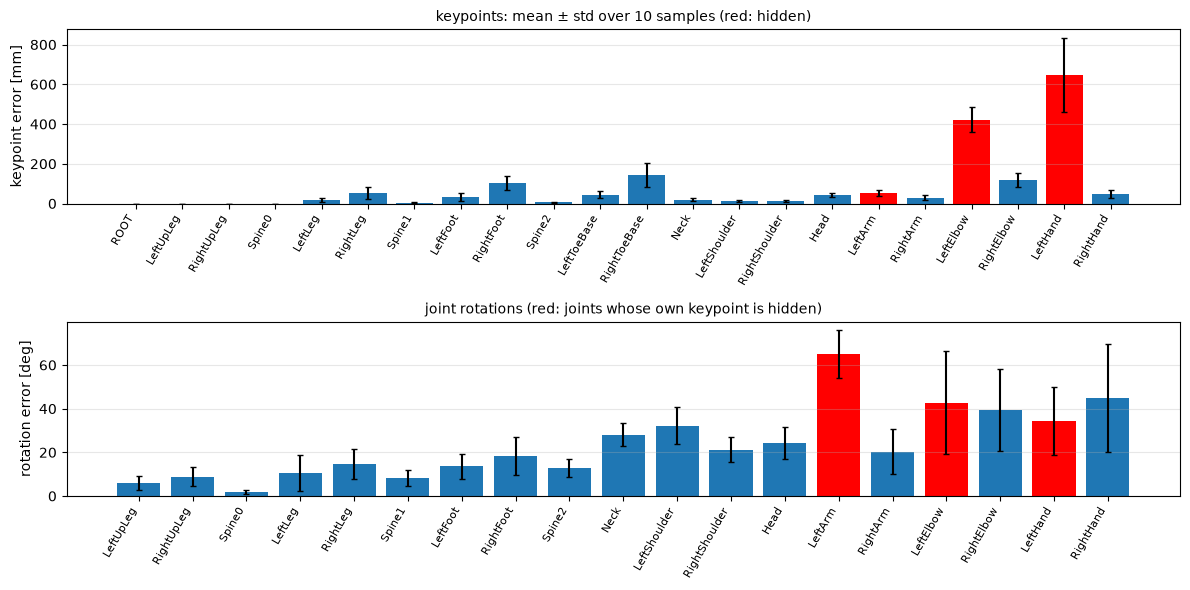

In [6]:
rot_err = torch.rad2deg(geodesic(samples, gt))                               # [N, 19]
fig, axes = plt.subplots(2, 1, figsize=(12, 6))
colors = ["red" if j in hidden else "C0" for j in range(22)]
axes[0].bar(range(22), err.mean(0), yerr=err.std(0), color=colors, capsize=2)
axes[0].set_xticks(range(22), NAMES22, rotation=60, ha="right", fontsize=8)
axes[0].set_ylabel("keypoint error [mm]")
axes[0].set_title(f"keypoints: mean ± std over {N_SAMPLES} samples (red: hidden)", fontsize=10)
names19 = [j.name for j in AmassJoints4Learning]
colors19 = ["red" if j.value in hidden else "C0" for j in AmassJoints4Learning]
axes[1].bar(range(J), rot_err.mean(0), yerr=rot_err.std(0), color=colors19, capsize=2)
axes[1].set_xticks(range(J), names19, rotation=60, ha="right", fontsize=8)
axes[1].set_ylabel("rotation error [deg]")
axes[1].set_title("joint rotations (red: joints whose own keypoint is hidden)", fontsize=10)
for ax in axes:
    ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

## 4. The occlusions of the paper on many poses

For `N_EVAL` random test poses and every occlusion of `OCCLUSIONS`: `K` samples per pose, and

- **1 sample**: the metrics of the first sample;
- **mean of K**: the metrics of the mean pose of the K samples (the "N = 10" of the paper);
- **best of K**: the smallest error among the K samples (min-of-N, Tab. 10 and Fig. 4).

MPJPE in mm over the 22 keypoints, MGEO in rad over the 19 joints, the log-likelihood of the ground truth given the visible keypoints. The paper's Tab. 3 reports "Ours (N = 10)" as MPJPE | MGEO: L 13.9 | 0.165, A+H 30.2 | 0.201, S+UA 12.7 | 0.162 (on the authors' AMASS release; ours is SMPL-X G, see `docs/model_comparison_paper_protocol.md`).

In [7]:
PAPER_TAB3 = {"L (left leg)": (13.9, 0.165), "A+H (left arm and hand)": (30.2, 0.201), "S+UA (right shoulder, upper arm)": (12.7, 0.162)}

g = torch.Generator().manual_seed(SEED + 1)
gt_eval = test[torch.randperm(len(test), generator=g)[:N_EVAL]]
kp_eval = keypoints(gt_eval)
rows = {}
for occlusion in OCCLUSIONS:
    hid = hidden_indices(occlusion)
    torch.manual_seed(SEED)
    s, _ = sample(kp_eval, hid, K)                                          # [N_EVAL, K, 19, 3, 3]
    kp_s = keypoints(s.reshape(-1, J, 3, 3)).reshape(N_EVAL, K, 22, 3)
    mpjpe = (kp_s - kp_eval[:, None]).norm(dim=-1).mean(-1) * 1000          # [N_EVAL, K]
    mgeo = geodesic(s, gt_eval[:, None]).mean(-1)                           # [N_EVAL, K]
    mean_pose = mean_rotation(s)
    mean_mpjpe = (keypoints(mean_pose) - kp_eval).norm(dim=-1).mean(-1) * 1000
    mean_mgeo = geodesic(mean_pose, gt_eval).mean(-1)
    ll = log_prob(gt_eval, kp_eval, hid)
    rows[occlusion] = dict(mpjpe_1=mpjpe[:, 0].mean(), mgeo_1=mgeo[:, 0].mean(), mpjpe_mean=mean_mpjpe.mean(), mgeo_mean=mean_mgeo.mean(),
                           mpjpe_best=mpjpe.min(1).values.mean(), mgeo_best=mgeo.min(1).values.mean(), ll=ll.mean(), ll_median=ll.median())

print(f"{N_EVAL} test poses, {K} samples each. MPJPE [mm] | MGEO [rad]\n")
print(f"{'occlusion':34s} {'1 sample':>15s} {f'mean of {K}':>15s} {f'best of {K}':>15s} {'paper N=10':>15s} {'log p(gt): mean':>16s} {'median':>7s}")
for occlusion, r in rows.items():
    paper = PAPER_TAB3.get(occlusion)
    paper = f"{paper[0]:5.1f} | {paper[1]:.3f}" if paper else "-"
    print(f"{occlusion:34s} {r['mpjpe_1']:5.1f} | {r['mgeo_1']:.3f} {r['mpjpe_mean']:7.1f} | {r['mgeo_mean']:.3f} "
          f"{r['mpjpe_best']:7.1f} | {r['mgeo_best']:.3f} {paper:>15s} {r['ll']:16.1f} {r['ll_median']:7.1f}")

1000 test poses, 10 samples each. MPJPE [mm] | MGEO [rad]

occlusion                                 1 sample      mean of 10      best of 10      paper N=10  log p(gt): mean  median
none                                18.3 | 0.234    11.7 | 0.168    11.8 | 0.168               -            182.5   186.0
L (left leg)                        21.2 | 0.246    14.2 | 0.176    14.0 | 0.179    13.9 | 0.165            177.9   181.4
A+H (left arm and hand)             38.6 | 0.283    30.6 | 0.207    23.0 | 0.203    30.2 | 0.201            173.4   177.6
S+UA (right shoulder, upper arm)    19.4 | 0.238    12.3 | 0.171    12.4 | 0.171    12.7 | 0.162            181.0   184.5
